# FactoryMind AI — Data Analysis
Exploratory analysis of the synthetic manufacturing sensor and production datasets.

In [1]:
import sys, os
sys.path.insert(0, '../src')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

machine_df = pd.read_csv('../data/machine_data.csv')
production_df = pd.read_csv('../data/production_data.csv')
machine_df.shape, production_df.shape

((4800, 15), (1440, 3))

## Dataset overview

In [2]:
machine_df.head()

,Machine_ID,Record_Index,Temperature,Vibration,Pressure,Rotational_Speed,Torque,Tool_Wear,Operating_Hours,Machine_Age_Years,Maintenance_Count,Production_Load,Target_Production,Production_Output,Failure
0,M-101,0,62.58,2.471,33.35,1457.9,40.78,13.04,4.9,7.08,0,0.653,652.6,623.6,0
1,M-101,1,60.80,3.339,30.80,1427.4,40.11,12.12,7.8,7.08,0,0.672,672.3,642.2,0
2,M-101,2,63.98,3.196,30.92,1417.0,38.62,12.53,14.8,7.08,0,0.578,577.9,528.5,0
3,M-101,3,63.98,3.277,31.80,1454.6,41.30,12.14,16.5,7.08,0,0.718,717.5,672.0,0
4,M-101,4,62.40,3.569,27.04,1429.1,42.75,12.84,20.5,7.08,0,0.924,924.2,866.1,0


In [3]:
machine_df.describe()

,Record_Index,Temperature,Vibration,Pressure,Rotational_Speed,Torque,Tool_Wear,Operating_Hours,Machine_Age_Years,Maintenance_Count,Production_Load,Target_Production,Production_Output,Failure
count,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000,4800.000000
mean,199.500000,71.254583,4.682187,35.063319,1398.955937,46.914738,45.357652,900.827375,5.567052,0.134792,0.698375,698.370396,533.557875,0.352708
std,115.481723,6.017115,1.193888,3.442323,35.289141,4.251632,21.476849,536.830721,2.016676,0.341536,0.149655,149.651776,137.617527,0.477863
min,0.000000,49.480000,1.421000,22.650000,1279.000000,34.300000,0.000000,0.700000,0.570000,0.000000,0.200000,200.000000,109.600000,0.000000
25%,99.750000,66.917500,3.759000,32.660000,1374.075000,43.740000,28.615000,438.375000,4.572500,0.000000,0.596000,596.175000,437.675000,0.000000
50%,199.500000,71.100000,4.625000,35.005000,1398.500000,46.775000,44.000000,883.400000,5.950000,0.000000,0.699000,699.000000,527.750000,0.000000
75%,299.250000,75.590000,5.608000,37.480000,1423.700000,50.130000,62.450000,1332.850000,6.780000,0.000000,0.797250,797.550000,623.625000,1.000000
max,399.000000,88.890000,7.961000,47.020000,1509.100000,59.940000,95.780000,2169.100000,8.630000,1.000000,1.150000,1150.000000,1036.500000,1.000000


In [4]:
machine_df['Failure'].value_counts(normalize=True)

Failure
0    0.647292
1    0.352708
Name: proportion, dtype: float64

## Sensor distributions by failure outcome

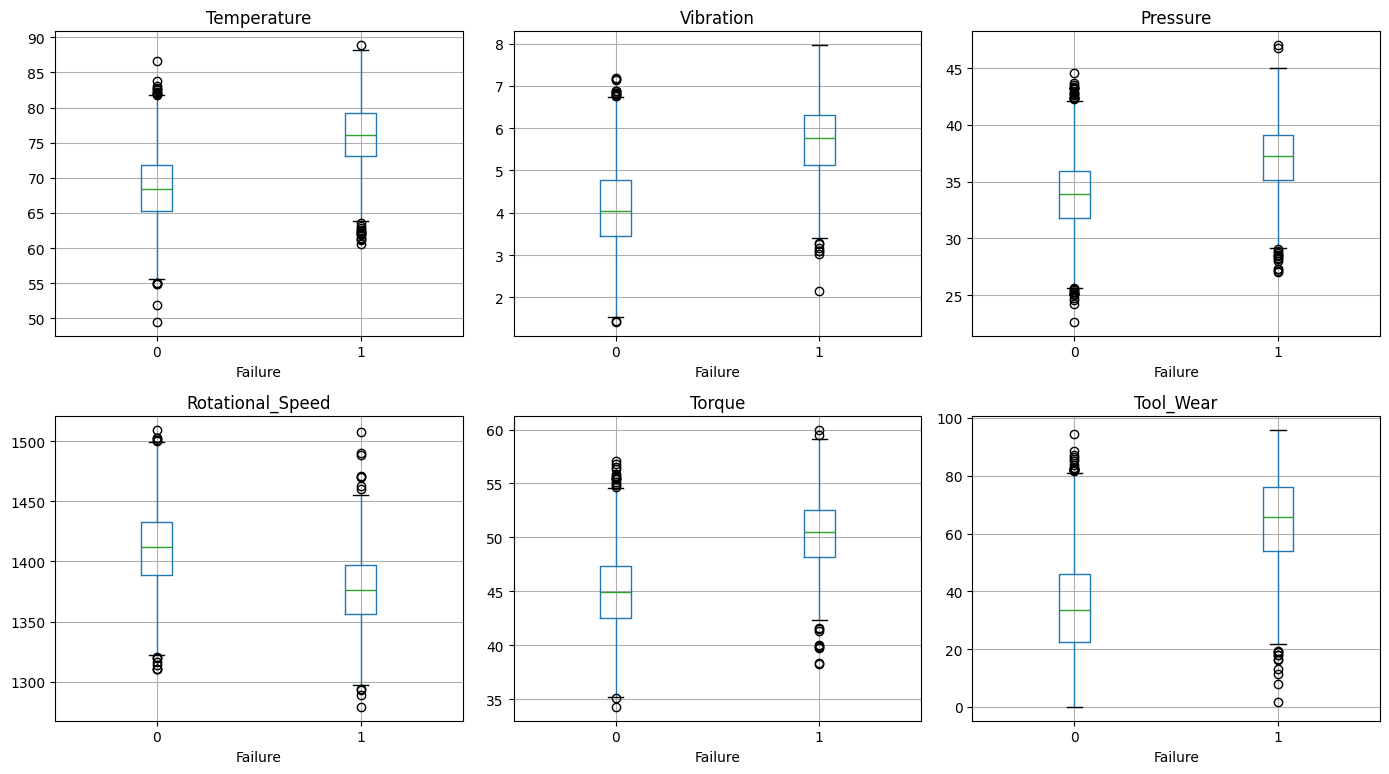

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
sensors = ['Temperature','Vibration','Pressure','Rotational_Speed','Torque','Tool_Wear']
for ax, col in zip(axes.flat, sensors):
    machine_df.boxplot(column=col, by='Failure', ax=ax)
    ax.set_title(col)
plt.suptitle('')
plt.tight_layout()
plt.show()

## Correlation with failure

In [6]:
corr = machine_df[sensors + ['Failure']].corr()['Failure'].drop('Failure').sort_values(ascending=False)
corr

Tool_Wear           0.649989
Vibration           0.631941
Temperature         0.600317
Torque              0.597084
Pressure            0.453219
Rotational_Speed   -0.454735
Name: Failure, dtype: float64

## Production trend for a sample machine

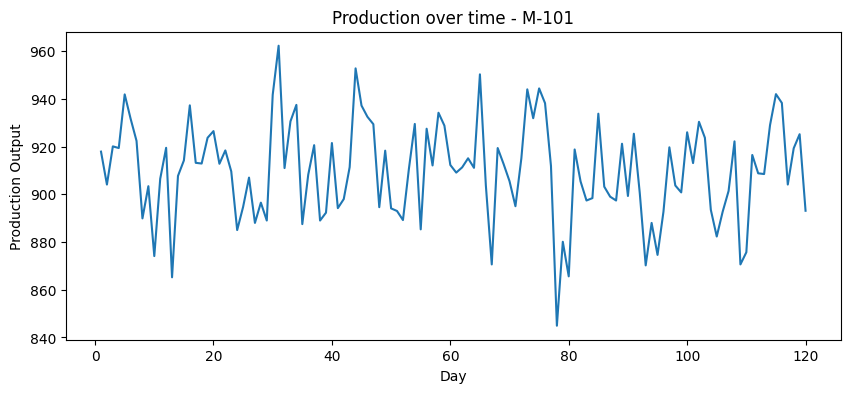

In [7]:
sample_machine = production_df['Machine_ID'].unique()[0]
sample = production_df[production_df['Machine_ID'] == sample_machine]
plt.figure(figsize=(10,4))
plt.plot(sample['Day'], sample['Production_Output'])
plt.title(f'Production over time - {sample_machine}')
plt.xlabel('Day'); plt.ylabel('Production Output')
plt.show()

## Takeaways
- Vibration, tool wear, and temperature are visibly higher in the failure group, confirming these are the sensors the failure model should key off.
- Production shows weekly seasonality plus a slow per-machine drift, motivating the GRU forecasting model in `forecast_model.py`.